In [ ]:
import fiona
from fiona.crs import from_epsg
from geopy.distance import distance, lonlat
import json
import math
import numpy as np
import pyproj
from shapely.geometry import Point, LineString, MultiLineString, mapping, shape
from shapely.ops import linemerge, transform, split, snap, unary_union
import tqdm
import matplotlib.pyplot as plt
from sword_le import swordle
import os


In [ ]:
sword_dir = ".data/SWORD_v17b_shp"
roi = 'ramier' #'ile_cite' #'ramier'
mask_path_ramier = ".data/masque_ramier/masque_ramier_polygone.shp"
topage_extraction_path_ramier = ".data/topage_extraction_ramier/topage_extraction_ramier_4326.shp"
mask_path = mask_path_ramier
topage_extraction_path = topage_extraction_path_ramier

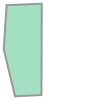

In [7]:
# Load mask
mask = shape(fiona.Collection(mask_path, "r")[0]["geometry"])
mask

In [ ]:
# Load source (SWORD)
src = fiona.Collection(os.path.join(sword_dir, "shp/EU/eu_sword_reaches_hb23_v17b.shp"), "r")
properties = src.schema["properties"]
properties

OrderedDict([('x', 'float:10.6'),
             ('y', 'float:10.6'),
             ('reach_id', 'str:11'),
             ('reach_len', 'float:13.6'),
             ('n_nodes', 'int:4'),
             ('wse', 'float:12.6'),
             ('wse_var', 'float:13.6'),
             ('width', 'float:13.6'),
             ('width_var', 'float:16.6'),
             ('facc', 'float:14.6'),
             ('n_chan_max', 'int:3'),
             ('n_chan_mod', 'int:3'),
             ('obstr_type', 'int:3'),
             ('grod_id', 'int:6'),
             ('hfalls_id', 'int:5'),
             ('slope', 'float:11.6'),
             ('dist_out', 'float:15.6'),
             ('lakeflag', 'int:3'),
             ('max_width', 'int:6'),
             ('n_rch_up', 'int:3'),
             ('n_rch_dn', 'int:3'),
             ('rch_id_up', 'str:50'),
             ('rch_id_dn', 'str:37'),
             ('swot_orbit', 'str:18'),
             ('swot_obs', 'int:3'),
             ('type', 'int:3')])

In [9]:
# Load replacement (TOPAGE extraction)
rep = fiona.Collection(topage_extraction_path, "r")
print("elements replacement data : ", len(rep))


elements replacement data :  3


In [10]:
src.schema, rep.schema

({'properties': OrderedDict([('x', 'float:10.6'),
               ('y', 'float:10.6'),
               ('reach_id', 'str:11'),
               ('reach_len', 'float:13.6'),
               ('n_nodes', 'int:4'),
               ('wse', 'float:12.6'),
               ('wse_var', 'float:13.6'),
               ('width', 'float:13.6'),
               ('width_var', 'float:16.6'),
               ('facc', 'float:14.6'),
               ('n_chan_max', 'int:3'),
               ('n_chan_mod', 'int:3'),
               ('obstr_type', 'int:3'),
               ('grod_id', 'int:6'),
               ('hfalls_id', 'int:5'),
               ('slope', 'float:11.6'),
               ('dist_out', 'float:15.6'),
               ('lakeflag', 'int:3'),
               ('max_width', 'int:6'),
               ('n_rch_up', 'int:3'),
               ('n_rch_dn', 'int:3'),
               ('rch_id_up', 'str:50'),
               ('rch_id_dn', 'str:37'),
               ('swot_orbit', 'str:18'),
               ('swot_obs', 'int:3'),


In [ ]:
# Load default attributes
with open(".data/default_attributes_v2.json", "r") as fin:
  default_attributes = json.load(fin)

In [12]:
# Reaches of src out of the mask
src_masked_out = swordle.select_reaches_using_mask(src, mask, where="out")

# Reaches of rep in and out of the mask
rep_masked_in = swordle.select_reaches_using_mask(rep, mask, where="in", crs=rep.crs)
rep_masked_out = swordle.select_reaches_using_mask(rep, mask, where="out", crs=rep.crs)


  - Selected 6097 portions (2 cut)
  - Selected 3 portions (3 cut)
  - Selected 2 portions (2 cut)


/home/aaiche/anaconda3/envs/swordle/lib/python3.8/site-packages/pyproj/crs/crs.py:130: FutureWarning: '+init=<authority>:<code>' syntax is deprecated. '<authority>:<code>' is the preferred initialization method. When making the change, be mindful of axis order changes: https://pyproj4.github.io/pyproj/stable/gotchas.html#axis-order-changes-in-proj-6
  in_crs_string = _prepare_from_proj_string(in_crs_string)


In [13]:
# Apply default attributes in selected replacement portions
print("- Apply default attributes in/out masked replacement layer")
rep_masked_in = swordle.apply_default_attributes(rep_masked_in, default_attributes)
rep_masked_out = swordle.apply_default_attributes(rep_masked_out, default_attributes)

- Apply default attributes in/out masked replacement layer


In [14]:
n_src_reaches=swordle.get_number_of_reaches_connected_to_mask(src, mask)
n_src_reaches

> geometry is  LineString
> mask boundary is  LineString
Point
> geometry is  LineString
> mask boundary is  LineString
Point


2

In [15]:
pairs=swordle.get_matching_src_rep_reaches_using_mask(src_masked_out, rep_masked_out, mask, 2)
print("> len pairs ! ", len(pairs))

> len pairs !  2


In [16]:
# Finding upstream and downstream reaches - Two reaches of source data that will be corrected to fit replacement data in ROI
src_upstream_reach, src_downstream_reach = swordle.find_upstream_downstream_reaches_using_mask(src_masked_out, mask)

In [17]:
# Finding closest intersection points to the mask between src up/dn data and rep data 
upstream_intersection_point = swordle.find_closest_intersection_point_to_the_mask(rep_masked_out, src_upstream_reach, mask)
downstream_intersection_point = swordle.find_closest_intersection_point_to_the_mask(rep_masked_out, src_downstream_reach, mask)

In [18]:
# Corrected upstream and downstream reaches
upstream_reach = swordle.correct_reach_using_intersection_point(
  rep = rep_masked_out,
  src_reach = src_upstream_reach,
  intersection_point = upstream_intersection_point,
  mask = mask)

downstream_reach = swordle.correct_reach_using_intersection_point(
  rep = rep_masked_out, 
  src_reach = src_downstream_reach,
  intersection_point = downstream_intersection_point,
  mask = mask)

NEW GEOM: LINESTRING (1.4090249733975602 43.517505852939316, 1.4093889263623445 43.517781040492, 1.4093818315301543 43.51805106437859, 1.4096715787971321 43.5183252184229, 1.4098871177722712 43.51859833947283, 1.4101768699126658 43.51887249228676, 1.410466624663044 43.51914664439403, 1.4108305939644517 43.519421827533584, 1.4111945665727175 43.519697009552445, 1.4114843298461717 43.51997115917371, 1.4117740957297917 43.52024530808822, 1.4119896508929723 43.52051842533681, 1.41220520797747 43.5207915421963, 1.4123465529715848 43.521063627929, 1.412562113556313 43.52133674414508, 1.4127034613696263 43.521608829455786, 1.4129190254547161 43.521881945028426, 1.413134591461298 43.52215506021195, 1.4133501593894084 43.52242817500631, 1.4134915131800754 43.522700259386276, 1.4137070846088196 43.522973373537106, 1.4139226579591975 43.52324648729876, 1.4140640161485531 43.523518571002285, 1.4142795929997671 43.523791684120354, 1.414495171772721 43.524064796849224, 1.4147107524674527 43.52433790

# Saving Results

In [19]:
upstream_intersection_point.x, upstream_intersection_point.y

(1.439115310046049, 43.55657422806986)

In [20]:
downstream_intersection_point.x, downstream_intersection_point.y

(1.4386039571797433, 43.59985523504509)

In [21]:
print(upstream_reach["properties"].keys())
print(src_downstream_reach["properties"].keys())


dict_keys([])
odict_keys(['x', 'y', 'reach_id', 'reach_len', 'n_nodes', 'wse', 'wse_var', 'width', 'width_var', 'facc', 'n_chan_max', 'n_chan_mod', 'obstr_type', 'grod_id', 'hfalls_id', 'slope', 'dist_out', 'lakeflag', 'max_width', 'n_rch_up', 'n_rch_dn', 'rch_id_up', 'rch_id_dn', 'swot_orbit', 'swot_obs', 'type'])


In [22]:
rectified_rep_features, upstream_reach, downstream_reach = swordle.adjust_reaches_with_confluence_using_mask(rep_masked_in, upstream_reach, downstream_reach, mask)

# Apply default attributes to elements to save
rectified_rep_features = swordle.apply_default_attributes(rectified_rep_features, default_attributes)

upstream_reach['properties'] = default_attributes
downstream_reach['properties'] = default_attributes

In [23]:
print(upstream_reach["properties"].keys())
print(downstream_reach["properties"].keys())


dict_keys(['reaches', 'nodes'])
dict_keys(['reaches', 'nodes'])


In [24]:
rectified_rep_features[0]["properties"]["reaches"].keys()

dict_keys(['x', 'y', 'reach_id', 'reach_len', 'n_nodes', 'wse', 'wse_var', 'width', 'width_var', 'max_width', 'facc', 'n_chan_max', 'n_chan_mod', 'obstr_type', 'grod_id', 'hfalls_id', 'slope', 'dist_out', 'lakeflag', 'n_rch_up', 'n_rch_dn', 'rch_id_up', 'rch_id_dn', 'swot_orbit', 'swot_obs', 'type'])

In [25]:
geometry = shape(downstream_reach["geometry"])
coords = list((geometry.coords))
lon1, lat1 = coords[0]
length1 = 0.0
    
for lon2, lat2 in coords[1:]:
    length1 += distance(lonlat(lon1, lat1), lonlat(lon2, lat2)).meters
    lon1, lat1 = lon2, lat2
downstream_reach["properties"]["reaches"]["reach_len"] = length1

In [26]:
coords[0]

(1.4290832999649654, 43.60270927235687)

In [27]:
geometry = shape(upstream_reach["geometry"])
coords = list((geometry.coords))
lon1, lat1 = coords[0]
length2 = 0.0
    
for lon2, lat2 in coords[1:]:
    length2 += distance(lonlat(lon1, lat1), lonlat(lon2, lat2)).meters
    lon1, lat1 = lon2, lat2
upstream_reach["properties"]["reaches"]["reach_len"] = length2

In [28]:
coords[0]

(1.4090249733975602, 43.517505852939316)

In [29]:
length1,length2

(1391.8290492138694, 5762.685284231805)

In [30]:
downstream_reach["properties"]["reaches"]["reach_len"]=length1
print(downstream_reach["properties"]["reaches"]["reach_len"])

1391.8290492138694


In [31]:
upstream_reach["properties"]["reaches"]["reach_len"]=length2
print(upstream_reach["properties"]["reaches"]["reach_len"])

5762.685284231805


In [33]:
# swordle.add_two_reaches_connection(upstream_reach, downstream_reach)

In [34]:
upstream_reach["properties"]["reaches"]["n_rch_dn"], upstream_reach["properties"]["reaches"]["rch_id_dn"]
downstream_reach["properties"]["reaches"]["n_rch_up"], downstream_reach["properties"]["reaches"]["rch_id_up"]

(-9, -9)

In [ ]:
# swordle.compute_connectivity(upstream_reach, downstream_reach, rep_masked_out)

In [1]:
#node=swordle.create_nodes(upstream_reach, default_attributes, spacing=200.0)